# Matched resistive attenuator

Optimize the topology of a resistive film into a matched 3 dB attenuator.

**Question.** A parallel-plate line carries a TEM wave between two lumped ports. Over
20 mm of its length, a horizontal sheet halfway up may be covered with a resistive
film of 300 Ω per square, or left bare: film or no film, nothing in between. Which
pattern absorbs half the power at 6 GHz ($|S_{21}|^2 = 1/2$, a 3 dB attenuator) and
reflects none of it?

The [topology tutorial](topology.ipynb) designs a dielectric *volume*. Here the
design is a *sheet*: a zero-thickness interior surface of the mesh whose film is
present or absent face by face. The chain is the same, with sheet pieces at the
end:

pixels $\rho$ → **Helmholtz filter** (length scale) → **projection** (towards film / no
film) → **layer grid** to the sheet's faces → **sheet field** (fill per face) →
{py:class}`~gfem.Impedance` on the sheet → {py:func}`gfem.solve` → $S_{11}$, $S_{21}$.

One trap shapes the whole page: a *partly* filled resistive sheet absorbs on its
own. An optimizer left with grey pixels will happily build the attenuator out of a
half-strength film that no process can make. The design is only done when the
pixels are binary, and the check is to threshold them and solve again.

**Assumptions.**

- Perfect conductors (PEC plates). The other walls are left unassigned, so they are
  magnetic walls (PMC) and the empty line carries an exact TEM wave.
- The film is a zero-thickness sheet of resistance $R_s = 300$ Ω per square, purely
  resistive (no sheet inductance), on an interior surface: one admittance term
  $1/R_s$ for the whole sheet (see {py:mod}`gfem.conventions`).
- Air everywhere else; the ports are resistors matched to the empty line.
- The mesh has sheet faces of about 0.5 mm² and the solve uses second-order
  Nédélec elements: plenty for the 50 mm wavelength at 6 GHz, but not for the field
  at the film's edges. Re-solves at orders 3 and 4 below show what that costs
  (about 0.04 in $|S_{21}|^2$).

**Conventions.** SI units at the API (the mesh file is in mm), time dependence
$e^{+i\omega t}$, S-parameters as power waves normalized to the port resistance, 1 W
incident. $1 - |S_{11}|^2 - |S_{21}|^2$ is then the power, in W, that the film absorbs.

In [1]:
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import pyvista as pv
from scipy.constants import epsilon_0, mu_0

import gfem
from gfem import design

pv.set_jupyter_backend("static")

GHz, mm = 1e9, 1e-3
F0 = 6 * GHz
FILM = 300.0  # ohm per square: the solid film

## The line

The mesh, {download}`data/sheet_line.msh`, is a 40 mm × 6 mm × 2 mm box along x.
Its surfaces are the plates `"plate1"` ($y = 0$) and `"plate2"` ($y = 6$ mm), the port
faces `"port1"` ($x = 0$) and `"port2"` ($x = 40$ mm), `"side"` ($z = 0$ and $z = 2$ mm,
left as PMC), and the interior surface `"sheet"`: the horizontal plane $z = 1$ mm over
$10\,\mathrm{mm} < x < 30\,\mathrm{mm}$, which splits the box into the volumes `"lower"` and `"upper"`.

The TEM field runs from plate to plate, E along y, so it lies *in* the sheet: a
film there carries current along y and absorbs. The line's characteristic
impedance is $\eta_0 d / h$ with $d = 6$ mm between the plates and $h = 2$ mm their height.
The film is weak against it: $\eta_0 / R_s = 1.26$, so a solid film is not a short.

In [2]:
mesh = gfem.Mesh.from_gmsh(Path("data/sheet_line.msh"), length_unit="mm")
z_line = np.sqrt(mu_0 / epsilon_0) * 6 / 2  # ohm: plates 6 mm apart, 2 mm high
AIR = gfem.Material(name="air")

line = gfem.Model(
    mesh,
    materials={"lower": AIR, "upper": AIR},
    boundaries=[gfem.PEC("plate1"), gfem.PEC("plate2")],
    ports=[
        gfem.LumpedPort("p1", "port1", "+y", impedance=z_line),
        gfem.LumpedPort("p2", "port2", "+y", impedance=z_line),
    ],
)
print(f"Z_line = {z_line:.0f} ohm, eta0 / R_s = {np.sqrt(mu_0 / epsilon_0) / FILM:.2f}")
line

Z_line = 1130 ohm, eta0 / R_s = 1.26


Model(Mesh(861 nodes, 2880 tetrahedra, volumes=['lower', 'upper'], surfaces=['port1', 'plate1', 'side', 'plate2', 'sheet', 'port2'], length_unit='mm')
  materials:
    lower: Material(name='air')
    upper: Material(name='air')
  boundaries:
    PEC(surface='plate1')
    PEC(surface='plate2')
  ports:
    LumpedPort(name='p1', surface='port1', direction=(0.0, 1.0, 0.0), resistance=None, inductance=None, capacitance=None, impedance=1130.1909402354154)
    LumpedPort(name='p2', surface='port2', direction=(0.0, 1.0, 0.0), resistance=None, inductance=None, capacitance=None, impedance=1130.1909402354154)
  default PMC (electromagnetic problems): side)

In 3D: the plates (grey, the near one see-through), the sheet's design area (tan,
with its faces), the two port faces (red) and the box. The wave travels along x;
its electric field points from one plate to the other.

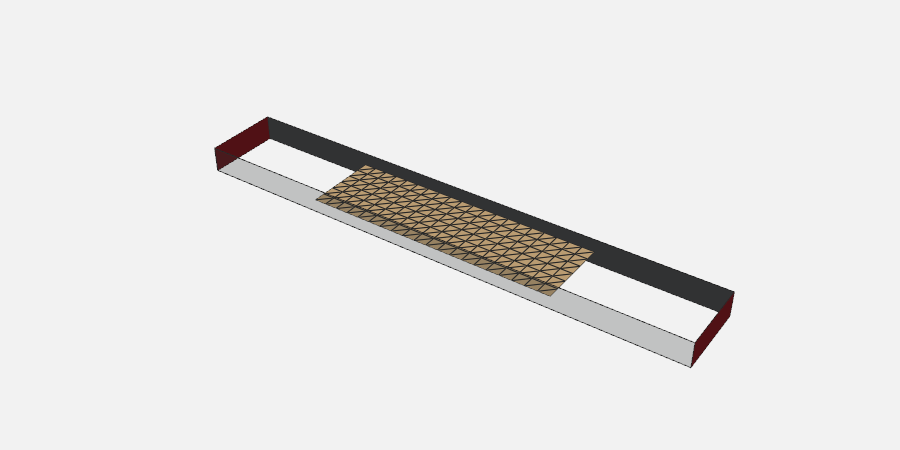

In [3]:
volumes = pv.from_meshio(mesh.to_meshio())  # tetrahedra first, then triangles
volumes.points /= mm
VIEW = (0.9, -1.3, 1.1)  # the camera's direction: above, from the plate1 side


def part(region):
    # A region of the mesh as a PyVista grid, in mm.
    cells = mesh.elements(region)
    if region in mesh.surfaces:
        cells = cells + len(mesh.tetrahedra)
    return volumes.extract_cells(cells)


view = pv.Plotter(window_size=(900, 450))
view.add_mesh(part("plate1"), color="grey", opacity=0.25)
view.add_mesh(part("plate2"), color="grey")
view.add_mesh(part("sheet"), color="tan", show_edges=True)
for face in ("port1", "port2"):
    view.add_mesh(part(face), color="#b5262f")
view.add_mesh(volumes.outline(), color="black")
view.view_vector(VIEW, viewup=(0, 0, 1))
view.camera.zoom(1.3)
view.show()

## From pixels to a film

{py:class}`~gfem.design.LayerGrid` lays 1 mm pixels over the sheet's footprint, 20
along x and 6 along y; `to_faces` gives each face of the sheet the bilinear
interpolation of the pixels at its centroid. The Helmholtz filter of radius 3 mm sets
the length scale, and `design.project` pushes the filtered image towards 0 (no film)
or 1 (film) with a sharpness $\beta$.

{py:meth}`gfem.SheetField.interpolate` turns that density into the fill $w$ that
scales the film's admittance face by face, $Y = w / R_s$. It is exponential,
$w = (c^\rho - 1) / (c - 1)$, with exact 0 and 1 at the ends: the fields feel a sheet over
several decades of admittance, and a linear fill would spend that whole range in the
first percent of the density. The contrast $c$ sets where in $\rho$ the film starts to
matter; a weak film ($\eta_0/R_s \approx 1$) takes a low one, here $c = 10^3$. See
{doc}`../recipes/sheet-design`.

Below, left: the fill against the density. Right: what a *uniform* film of each
density does to the line at 6 GHz. Near $\rho \approx 0.6$ a uniform grey film already gives
$|S_{21}|^2 = 1/2$ with little reflection. That is the trap: grey pixels are a cheap
attenuator, and only the projection keeps the optimizer from using them.

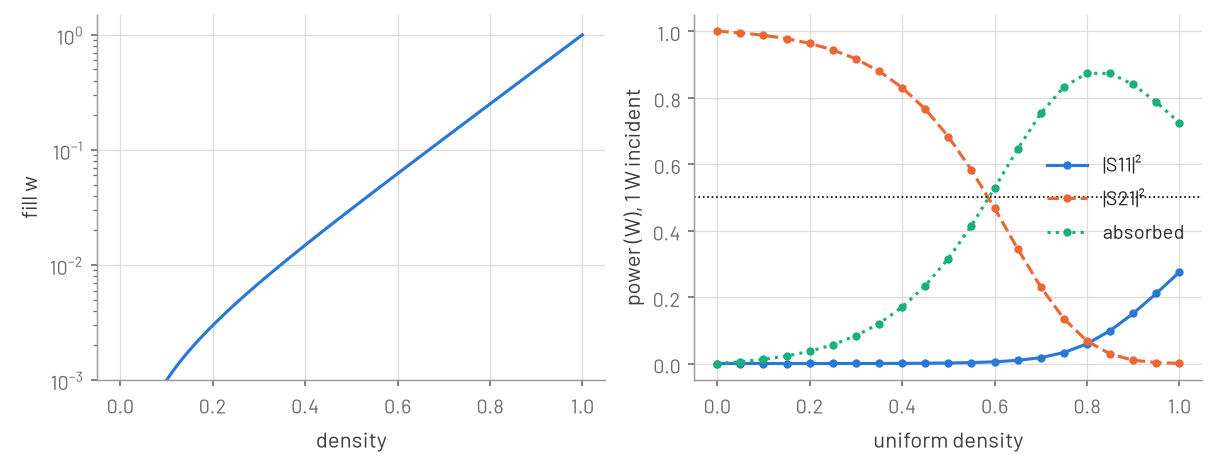

In [4]:
grid = design.LayerGrid(mesh, "sheet", pitch=1 * mm)
blur = design.helmholtz_filter(grid, radius=3 * mm)
CONTRAST = 1e3
problem = gfem.Driven(frequency=F0, excite="p1")
options = gfem.SolverOptions(linear_solver="direct")


def sheet_fill(density):
    # A density per pixel (0 bare, 1 film) -> the fill of each face of the sheet.
    return gfem.SheetField.interpolate(grid.to_faces(density), contrast=CONTRAST)


def solve(fill, problem=problem, order=None):
    film = gfem.Impedance("sheet", resistance=FILM, fill=fill)
    model = line.replace(boundaries=[*line.boundaries, film])
    opts = (
        options
        if order is None
        else gfem.SolverOptions(linear_solver="direct", order=order)
    )
    return gfem.solve(model, problem, options=opts)


def powers(s):
    # |S11|^2, |S21|^2 and the absorbed power 1 - |S11|^2 - |S21|^2, per frequency.
    r = np.abs(np.asarray(s["p1", "p1"])) ** 2
    t = np.abs(np.asarray(s["p2", "p1"])) ** 2
    return r, t, 1 - r - t


rho_axis = np.linspace(0, 1, 101)
uniform = np.linspace(0, 1, 21)
sweep = np.array(
    [
        [p[0] for p in powers(solve(sheet_fill(jnp.full(grid.shape, u))).s)]
        for u in uniform
    ]
)

fig, (left, right) = plt.subplots(1, 2, figsize=(8, 3), layout="constrained")
left.semilogy(rho_axis, (CONTRAST**rho_axis - 1) / (CONTRAST - 1))
left.set(xlabel="density", ylabel="fill w", ylim=(1e-3, 1.5))
for column, label in zip(sweep.T, ("|S11|²", "|S21|²", "absorbed"), strict=True):
    right.plot(uniform, column, marker="o", ms=3, label=label)
right.axhline(0.5, color="k", lw=0.8, ls=":")
right.set(xlabel="uniform density", ylabel="power (W), 1 W incident")
right.legend();

## The objective

The squared distance to the target, $(|S_{21}|^2 - 1/2)^2 + |S_{11}|^2$, at 6 GHz with port 1
excited: zero for a matched 3 dB attenuator.

In [5]:
def loss(rho, beta):
    s = solve(sheet_fill(design.project(blur(rho), beta=beta))).s
    s11, s21 = s["p1", "p1"][0], s["p2", "p1"][0]
    return (jnp.abs(s21) ** 2 - 0.5) ** 2 + jnp.abs(s11) ** 2


value_and_grad = jax.jit(jax.value_and_grad(loss))

## Optimize

Adam on the raw pixels, step 0.05, clipped to [0, 1], from a grey 0.5 with a little
noise. The sharpness $\beta$ doubles from 2 to 64, 15 steps each. The early, soft steps
let the film move; the late, sharp ones leave no room for grey. Stopping early is
the trap above: at $\beta = 8$ the loss can be small while no pixel is binary yet. So the
loop also records the **binary fraction**, the share of projected pixels within
0.05 of 0 or 1.

In [6]:
BETAS, STEPS_PER_BETA = (2.0, 4.0, 8.0, 16.0, 32.0, 64.0), 15
rho = 0.5 + 0.01 * jax.random.normal(jax.random.key(1), grid.shape)
optimizer = optax.adam(0.05)
state = optimizer.init(rho)
history = []  # (loss, binary fraction) per step
for beta in BETAS:
    for _ in range(STEPS_PER_BETA):
        value, g = value_and_grad(rho, beta)
        updates, state = optimizer.update(g, state)
        rho = jnp.clip(optax.apply_updates(rho, updates), 0.0, 1.0)
        projected = design.project(blur(rho), beta=beta)
        binary = float(jnp.mean((projected < 0.05) | (projected > 0.95)))
        history.append((float(value), binary))
    print(f"beta = {beta:3.0f}: loss = {float(value):.2e}, binary = {binary:.0%}")

beta =   2: loss = 3.38e-03, binary = 0%


beta =   4: loss = 6.48e-03, binary = 0%


beta =   8: loss = 1.66e-04, binary = 0%


beta =  16: loss = 2.22e-03, binary = 37%


beta =  32: loss = 1.74e-04, binary = 88%


beta =  64: loss = 1.78e-04, binary = 99%


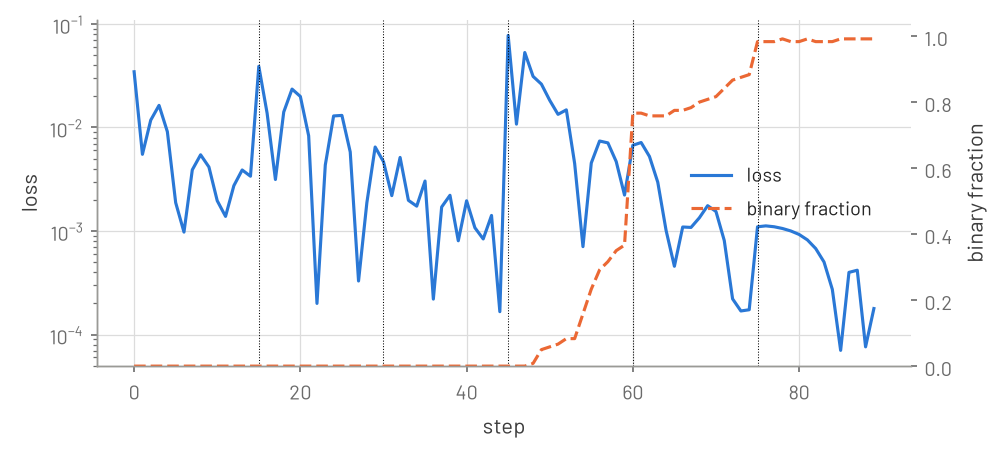

In [7]:
steps = np.arange(len(history))
fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy(steps, [h[0] for h in history], label="loss")
ax.set(xlabel="step", ylabel="loss")
twin = ax.twinx()
twin.plot(steps, [h[1] for h in history], color="C1", ls="--", label="binary fraction")
twin.set(ylabel="binary fraction", ylim=(0, 1.05))
twin.grid(False)
for k in range(1, len(BETAS)):
    ax.axvline(k * STEPS_PER_BETA, color="k", lw=0.5, ls=":")
fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.5));

## The design

`final` is the last density thresholded at 0.5. Even a binary pixel image is not a
binary film yet: each face samples the pixels bilinearly at its centroid, so faces
along the pattern's edges would get a fractional fill. So the faces are thresholded
too: `final_fill` is exactly 1 (film) or 0 (bare) on every face, the film as it
would be made on this mesh. Every number after this comes from it.

Left, the projected density at $\beta = 64$; right, `final`, with the plates (grey bars) at
$y = 0$ and $y = 6$ mm and the wave coming in from the left.

faces the bilinear sampling would leave grey: 18%
final: |S11|^2 = 0.0047, |S21|^2 = 0.4682, absorbed = 0.5271 W
film on 29% of the pixels


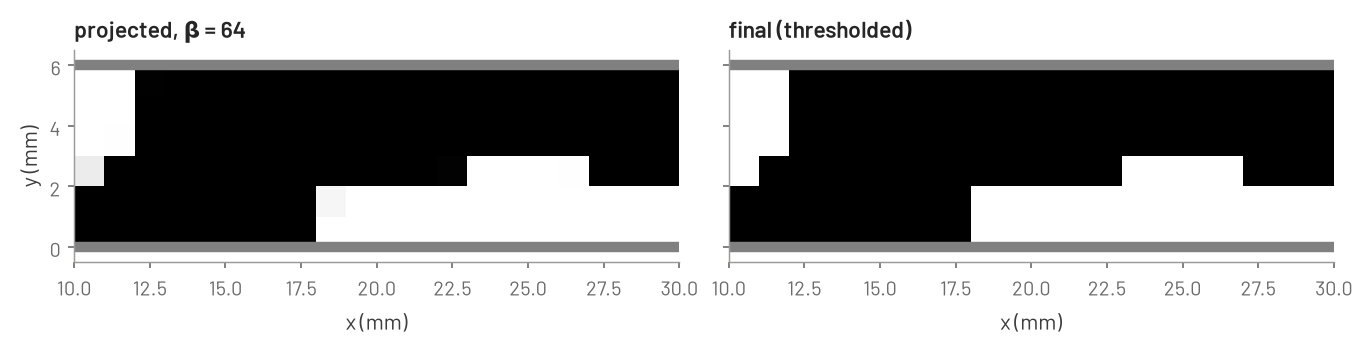

In [8]:
last = design.project(blur(rho), beta=BETAS[-1])
final = (last > 0.5).astype(float)
faces_density = np.asarray(grid.to_faces(final))
grey = np.mean((faces_density > 0) & (faces_density < 1))
final_fill = gfem.SheetField((faces_density > 0.5).astype(float))
r0, t0, a0 = (p[0] for p in powers(solve(final_fill).s))
print(f"faces the bilinear sampling would leave grey: {grey:.0%}")
print(f"final: |S11|^2 = {r0:.4f}, |S21|^2 = {t0:.4f}, absorbed = {a0:.4f} W")
print(f"film on {float(final.mean()):.0%} of the pixels")

x0, y0 = np.asarray(grid.origin) / mm
ny, nx = grid.shape
extent = (x0, x0 + nx * grid.pitch / mm, y0, y0 + ny * grid.pitch / mm)
fig, axes = plt.subplots(1, 2, figsize=(9, 2.6), sharey=True, layout="constrained")
for ax, image, title in zip(
    axes,
    (last, final),
    (f"projected, β = {BETAS[-1]:.0f}", "final (thresholded)"),
    strict=True,
):
    ax.imshow(image, origin="lower", extent=extent, cmap="gray", vmin=0, vmax=1)
    for y in (0, 6):
        ax.axhline(y, color="grey", lw=5)
    ax.set(title=title, xlabel="x (mm)", ylim=(-0.5, 6.5))
    ax.grid(False)
axes[0].set_ylabel("y (mm)");

What the pattern is. No film strip bridges the two plates; a strip from plate to
plate would be a plain resistor across the line. Instead there are two patches, each
touching *one* plate: a short one on `"plate2"` where the sheet begins
($10\,\mathrm{mm} < x < 12\,\mathrm{mm}$) and a longer one on `"plate1"` ($18\,\mathrm{mm} < x < 30\,\mathrm{mm}$). The film's
current flows in from its plate along y and has to cross the rest of the gap to the
other plate as displacement current. So each patch loads the line as a film
resistance in series with a gap capacitance. The capacitance makes the load depend
on frequency, as the spectrum below shows.

In 3D, the same view as the line above: the film (tan) on the sheet between the
plates.

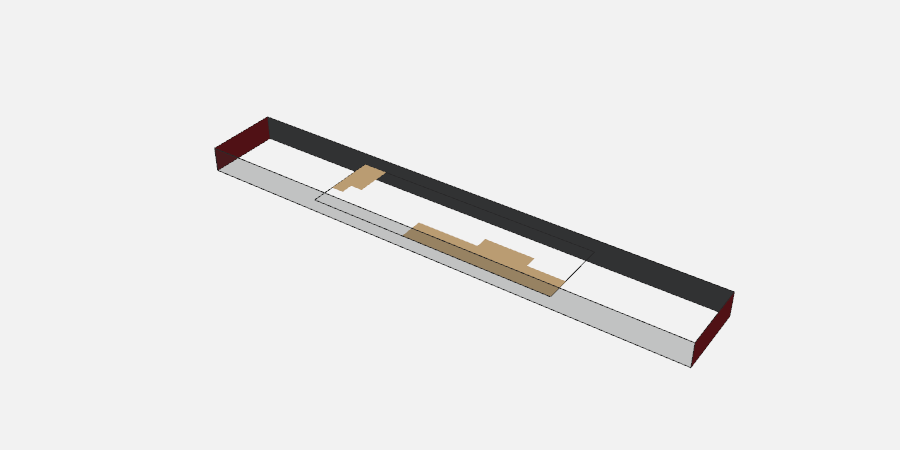

In [9]:
faces = part("sheet")
faces.cell_data["film"] = np.asarray(final_fill.fill)
view = pv.Plotter(window_size=(900, 450))
view.add_mesh(part("plate1"), color="grey", opacity=0.25)
view.add_mesh(part("plate2"), color="grey")
view.add_mesh(faces.threshold(0.5, scalars="film"), color="tan")
view.add_mesh(faces.extract_feature_edges(), color="black")
for face in ("port1", "port2"):
    view.add_mesh(part(face), color="#b5262f")
view.add_mesh(volumes.outline(), color="black")
view.view_vector(VIEW, viewup=(0, 0, 1))
view.camera.zoom(1.3)
view.show()

## Where the power goes

Two checks on `final` at 6 GHz, from one solve that keeps the field.

- **Power balance.** The only loss in the model is the film, so the power it
  absorbs, integrated from the field, must equal $1 - |S_{11}|^2 - |S_{21}|^2$. On the sheet
  the film dissipates $p = \tfrac{1}{2} (w / R_s) |E_t|^2$ per unit area (peak phasors), with $E_t$
  the field tangential to the sheet and $w$ the face's fill (0 or 1). `absorbed_power`
  sums it over the sheet's faces, sampling each face at the centroids of 16
  sub-triangles.
- **The order.** Third- and fourth-order elements on the same mesh show the field
  discretization error, as a change of $|S_{21}|^2$.

In [10]:
kept = solve(final_fill, gfem.Driven(frequency=F0, excite="p1", keep_fields=True))
field = kept.e_field(F0, excite="p1")
nodes = np.asarray(mesh.nodes)
triangles = nodes[np.asarray(mesh.triangles)[mesh.elements("sheet")]]  # (faces, 3, 3)
fill = np.asarray(final_fill.fill)

# Barycentric centroids of the 16 sub-triangles of a 4 x 4 split.
n = 4
bary = [((i + 1 / 3) / n, (j + 1 / 3) / n) for i in range(n) for j in range(n - i)]
bary += [
    ((i + 2 / 3) / n, (j + 2 / 3) / n) for i in range(n - 1) for j in range(n - 1 - i)
]
bary = np.array([(a, b, 1 - a - b) for a, b in bary])
points = np.einsum("qk,fkc->fqc", bary, triangles)  # (faces, 16, 3)
e = np.asarray(field.at(points.reshape(-1, 3))).reshape(*points.shape[:2], 3)
e_t2 = np.sum(np.abs(e[..., :2]) ** 2, axis=-1)  # the sheet is horizontal: E_x, E_y
area = 0.5 * np.linalg.norm(
    np.cross(triangles[:, 1] - triangles[:, 0], triangles[:, 2] - triangles[:, 0]),
    axis=1,
)
density_w = 0.5 * fill[:, None] / FILM * e_t2  # W / m^2 at each sample
absorbed_power = float(np.sum(density_w.mean(axis=1) * area))
print(f"film loss from the field: {absorbed_power:.4f} W")
print(f"1 - |S11|^2 - |S21|^2:    {a0:.4f} W")

for order in (3, 4):
    r_o, t_o, _ = (p[0] for p in powers(solve(final_fill, order=order).s))
    print(f"order {order}: |S21|^2 = {t_o:.4f} (delta {t_o - t0:+.1e}), ", end="")
    print(f"|S11|^2 = {r_o:.4f}")

film loss from the field: 0.5263 W
1 - |S11|^2 - |S21|^2:    0.5271 W


order 3: |S21|^2 = 0.4939 (delta +2.6e-02), |S11|^2 = 0.0039


order 4: |S21|^2 = 0.5045 (delta +3.6e-02), |S11|^2 = 0.0035


Where the film absorbs: the loss density on the sheet (W/m², 1 W incident), face by
face, with the film's edges in red. The short patch at the entry takes the larger
share of the power, though it is a fifth of the film's area.

absorbed in the entry patch: 0.349 W of 0.526 W
its share of the film area: 20%


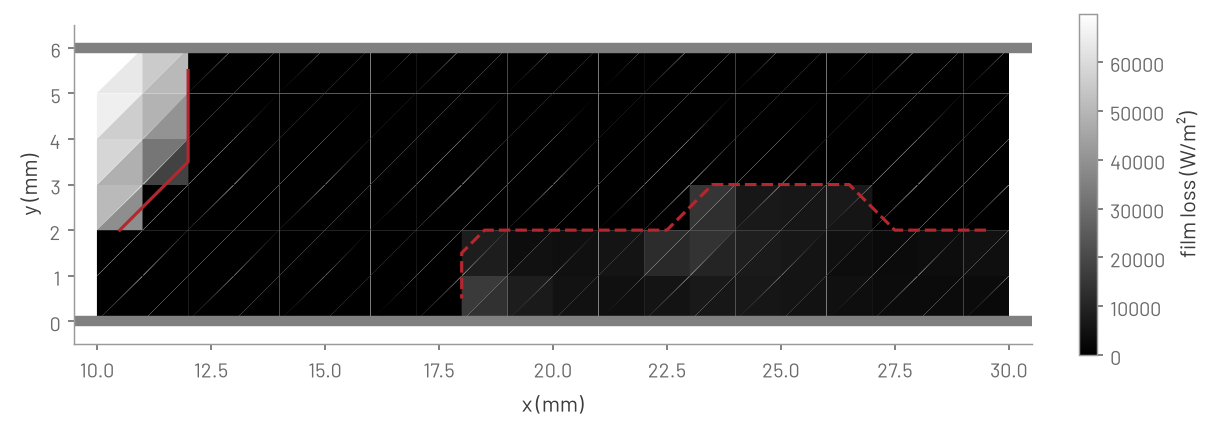

In [11]:
from contourpy import contour_generator
from matplotlib.collections import PolyCollection

x_centres = x0 + (np.arange(nx) + 0.5) * grid.pitch / mm  # pixel centres, mm
y_centres = y0 + (np.arange(ny) + 0.5) * grid.pitch / mm
fig, ax = plt.subplots(figsize=(8, 2.8), layout="constrained")
faces2d = PolyCollection(
    triangles[:, :, :2] / mm, array=density_w.mean(axis=1), cmap="gray"
)
ax.add_collection(faces2d)
edge = contour_generator(x_centres, y_centres, np.asarray(final)).lines(0.5)
for segment in edge:
    ax.plot(*segment.T, color="#b5262f", lw=1.5)
for y in (0, 6):
    ax.axhline(y, color="grey", lw=5)
ax.set(
    xlim=(9.5, 30.5), ylim=(-0.5, 6.5), xlabel="x (mm)", ylabel="y (mm)", aspect="equal"
)
ax.grid(False)
fig.colorbar(faces2d, ax=ax, label="film loss (W/m²)")
entry = triangles[:, :, 0].mean(axis=1) < 15 * mm  # the patch at the sheet's start
per_face = density_w.mean(axis=1) * area
film_area = area[fill > 0].sum()
print(f"absorbed in the entry patch: {per_face[entry].sum():.3f} W", end="")
print(f" of {per_face.sum():.3f} W")
print(f"its share of the film area: {area[entry & (fill > 0)].sum() / film_area:.0%}")

The field itself, $|E|$ on the sheet's plane and on a cut across the line at $x = 20$ mm,
with the film in tan. The wave enters at full strength from port 1, and leaves
through port 2 at about $1/\sqrt{2}$ of it.

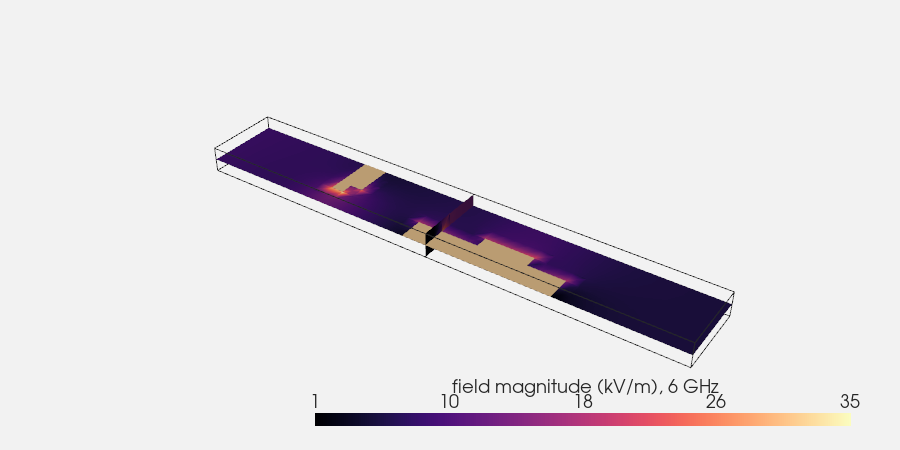

In [12]:
sampled = field.to_pyvista()
sampled.points /= mm
sampled["|E| (kV/m)"] = (
    np.linalg.norm(sampled["E_real"] + 1j * sampled["E_imag"], axis=1) / 1e3
)
view = pv.Plotter(window_size=(900, 450))
view.add_mesh(
    sampled.slice(normal="z", origin=(0, 0, 1.0)),
    scalars="|E| (kV/m)",
    cmap="magma",
    scalar_bar_args={"title": "field magnitude (kV/m), 6 GHz", "fmt": "%.0f"},
)
view.add_mesh(
    sampled.slice(normal="x", origin=(20, 0, 0)),
    scalars="|E| (kV/m)",
    cmap="magma",
    show_scalar_bar=False,
)
view.add_mesh(faces.threshold(0.5, scalars="film").translate((0, 0, 0.02)), color="tan")
view.add_mesh(volumes.outline(), color="black")
view.view_vector(VIEW, viewup=(0, 0, 1))
view.camera.zoom(1.3)
view.show()

## The spectrum

`final` from 2 to 10 GHz. The reflection stays small across the whole band, but the
attenuation is not flat: the absorbed power grows with frequency, as for a load
coupled through a capacitance. The design is a 3 dB attenuator at 6 GHz only.

max |S11|^2 over 2-10 GHz: 0.064
absorbed: 0.10 W at 2 GHz, 0.65 W at 10 GHz


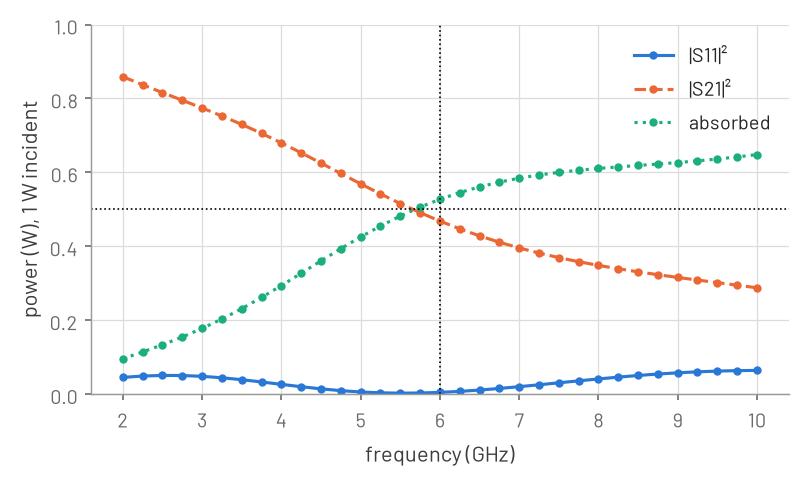

In [13]:
frequencies = np.linspace(2, 10, 33) * GHz
r, t, a = powers(solve(final_fill, gfem.Driven(frequency=frequencies, excite="p1")).s)
fig, ax = plt.subplots(figsize=(6, 3.2))
for values, label in zip((r, t, a), ("|S11|²", "|S21|²", "absorbed"), strict=True):
    ax.plot(frequencies / GHz, values, marker="o", ms=3, label=label)
ax.axvline(F0 / GHz, color="k", lw=0.8, ls=":")
ax.axhline(0.5, color="k", lw=0.8, ls=":")
ax.set(xlabel="frequency (GHz)", ylabel="power (W), 1 W incident", ylim=(0, 1))
ax.legend()
print(f"max |S11|^2 over 2-10 GHz: {r.max():.3f}")
print(f"absorbed: {a[0]:.2f} W at 2 GHz, {a[-1]:.2f} W at 10 GHz")

## Limits

- **Binary only after a long continuation.** The design is fabricable only because
  $\beta$ reaches 64; stopped at $\beta = 8$, the same loop ends on an all-grey film that
  thresholding turns into a near-short. Always threshold and re-solve, as here.
- **One frequency.** The objective sees 6 GHz only, and the attenuation rises with
  frequency (the spectrum above). A flat attenuator would sum the objective over
  frequencies.
- **The order is not converged.** $|S_{21}|^2$ of `final` is 0.468 at order 2 (the
  order the optimization ran at), 0.494 at order 3 and 0.505 at order 4: it moves
  by more than the design misses its target by. The field gathers at the film's edges
  and corners, which the mesh resolves coarsely. A design meant to be built would be
  optimized at order 3, on a mesh refined at the sheet, and checked again.
- **A length scale from the filter only.** The 3 mm filter radius gives the film a
  length scale, not a minimum feature size, and the design is not tolerant to an
  over- or under-etch of the film's edges. The
  {doc}`../recipes/robust-optimization` recipe optimizes the eroded, nominal and
  dilated designs together, as the [topology tutorial](topology.ipynb) does.
- **Coarse pixels.** 1 mm pixels on 6 mm × 20 mm: 120 parameters. The pattern's
  edges are staircases at the pixel pitch. During the optimization, faces along the
  edges take fractional fills from the bilinear sampling; `final_fill` thresholds
  them, so the optimized and the checked film differ at the edges. The mesh is part
  of the film model.
- **An ideal film and line.** A purely resistive, zero-thickness sheet in air
  between perfect plates with magnetic side walls. A real film has a thickness,
  a substrate and contacts to the plates, and a real line has fringing fields.

## Next

- {doc}`../recipes/sheet-design`: sheet designs in general (which surfaces,
  conductors and superconductors, solvers, what raises).
- {doc}`../recipes/s-parameter-gradient`: what is differentiable in a driven solve.
- {py:mod}`gfem.design` reference: `LayerGrid`, `helmholtz_filter`, `project`.